# Chan et al. 2021 — Lung (SCLC) · 04 Expression (unconditional EMT-TF step)

*(Renumbered from 06: with **Gate 1 = GO, Gate 2 = GO (non-branching), Gate 3 = NA** the manifold is
non-branching, so the branching-only `04_correlation` / `05_modules` notebooks are not produced; the
unconditional EMT-TF step becomes the final notebook, numbered 04.)*

EMT-TF expression overlaid on the manifold. A widened mesenchymal panel (Snail/Zeb/Twist **and**
FOXC/PRRX families — VIM is a marker, not a TF, and is excluded) scored on this dataset, gated on
detectable expression, ordered by pseudotime.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth,'data')
pth_in  = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude','Lung',name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude','Lung',name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

### Load `signatures.h5ad`; use house linear layout

In [2]:
adata = sc.read_h5ad(os.path.join(pth_in,'signatures.h5ad')); print(adata.n_obs,'cells')
adata.obsm['X_umap'] = adata.obsm['X_umap_lin'].copy()

50881 cells


### EMT-TF panel — detection-gated, pseudotime-ordered

Widened panel beyond Snail/Zeb/Twist to include FOXC/PRRX. For each TF: fraction expressing, mean in
the early (root) vs late (terminus) pseudotime tercile, and Spearman vs pseudotime. Endpoint markers
are drawn from factors above the 3% detection floor — the most root-leaning and most
terminus-leaning.

In [3]:
cands = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in cands if g in adata.var_names]
t = adata.obs['t'].values; q1,q2 = np.quantile(t,1/3), np.quantile(t,2/3)
rows=[]
for g in present:
    x = np.asarray(adata[:,g].X.todense()).ravel()
    frac = (x>0).mean()
    if frac < 0.03:
        print(f'{g}: frac={frac:.3f} -> below 3% detection floor, dropped'); continue
    rho = spearmanr(x,t).correlation
    rows.append((g, frac, rho, x[t<q1].mean(), x[t>q2].mean()))
df = pd.DataFrame(rows, columns=['gene','frac','rho_t','early_mean','late_mean']).sort_values('rho_t')
print(df.round(3).to_string(index=False))
root_tf, term_tf = df.iloc[0]['gene'], df.iloc[-1]['gene']
print(f'\nroot-leaning TF: {root_tf}  |  terminus-leaning TF: {term_tf}')

TWIST2: frac=0.004 -> below 3% detection floor, dropped
FOXC2: frac=0.016 -> below 3% detection floor, dropped
PRRX1: frac=0.016 -> below 3% detection floor, dropped
PRRX2: frac=0.024 -> below 3% detection floor, dropped
  gene  frac  rho_t  early_mean  late_mean
TWIST1 0.139 -0.107       0.140      0.090
  ZEB2 0.122 -0.072       0.091      0.079
  ZEB1 0.227 -0.057       0.171      0.167
 SNAI2 0.055 -0.031       0.035      0.037
 FOXC1 0.154 -0.029       0.096      0.110
 SNAI1 0.121 -0.011       0.064      0.085

root-leaning TF: TWIST1  |  terminus-leaning TF: SNAI1


### Deliverable — `expression.pdf`: thresholded expressers on a grey manifold

House style: categorical overlay (not a continuous colormap). Cells above the upper quartile of
expression **among expressers** are coloured per TF over the grey manifold; the more abundant factor
is drawn first so the sparser one stays visible. `figsize=(3.5,1.5)`.

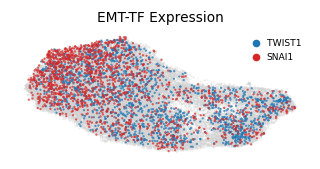

In [4]:
tfs = {root_tf:'tab:blue', term_tf:'tab:red'}
order = sorted(tfs, key=lambda g: -(np.asarray(adata[:,g].X.todense()).ravel()>0).mean())
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.35, frameon=False, show=False, ax=ax)
handles=[]
for g in order:
    x = np.asarray(adata[:,g].X.todense()).ravel(); expr = x[x>0]
    thr = np.quantile(expr,.75) if expr.size else np.inf
    sub = adata[x>thr]
    sc.pl.umap(sub, na_color=tfs[g], size=9, alpha=.7, frameon=False, show=False, ax=ax)
    handles.append(plt.Line2D([0],[0], marker='o', ls='', color=tfs[g], label=g, ms=4))
ax.legend(handles=handles, loc='upper right', fontsize=6, frameon=False, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=9)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()